# K-nearest-neighbor and Nadaraya–Watson regression for student grades

This standalone notebook compares two **local constant regression** methods on the ST5227 student-grade task. K-nearest-neighbor (KNN) regression averages the outcomes of the closest `k` students; Gaussian Nadaraya–Watson (NW) regression gives every training student a smooth distance-based weight. Both use the same target, exclusions, duplicate handling, log-income transform, and 85/15 split as `Project.ipynb` and `Project-GAMs.ipynb`. Every learned preprocessing and selection step is fitted within the relevant training fold.

The Week 5 lecture defines KNN and NW as related local averages, and its lab demonstrates Gaussian local constant regression using `statsmodels.KernelReg` on a one-dimensional motorcycle dataset. Here `statsmodels.KernelReg` applies the same Gaussian local-constant regression to the selected or full encoded feature spaces used for KNN. This is **local constant**, not local linear, regression. We compare both with mean-only, OLS, and a fixed-settings forest reference using grade-point RMSE. The shared test partition has already been inspected in the project; its scores here are **corroborative**, not a fresh confirmatory test.

Run from this notebook's folder or its parent project folder in the Python 3.14 environment with scikit-learn and statsmodels. Data source: `student_grade_ses_dataset.csv`. Course source: `Lessons/05-Nonparametric_Regression/Week 5 - Nonparametric Methods.pdf` and its lab notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold, train_test_split
from sklearn.neighbors import KNeighborsRegressor, NearestNeighbors
from statsmodels.nonparametric.kernel_regression import KernelReg
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
TEST_SIZE = 0.15
OUTER_SPLITS = 5
INNER_SPLITS = 3
K_GRID = [1, 5, 15, 40, 100, 250, 500]
FEATURE_GRID = [10, "all"]
WEIGHT_GRID = ["uniform", "distance"]
NW_BANDWIDTH_MULTIPLIERS = [0.05, 0.1, 0.2, 0.4, 0.8, 1.6]
TARGET = "final_grade_pct"
FOREST_SETTINGS = dict(n_estimators=120, min_samples_leaf=10,
                       max_features=0.7, n_jobs=-1)

print("scikit-learn:", sklearn.__version__)
print("Outer folds:", OUTER_SPLITS, "| inner folds:", INNER_SPLITS)
print("K grid:", K_GRID, "| encoded feature counts:", FEATURE_GRID)


scikit-learn: 1.9.0
Outer folds: 5 | inner folds: 3
K grid: [1, 5, 15, 40, 100, 250, 500] | encoded feature counts: [10, 'all']


## Data preparation and feature exploration

Predict the final percentage grade from student and socioeconomic variables. Exclude `grade_class` and `at_risk_flag` because they are derived from the target; exclude the ID and survey date from prediction. Keep missing values until each fold fits its own imputation. Log income to reduce its skew. The following descriptive plots do not select features for fitting.

12,025 records; 25 exact duplicates removed; 12,000 students remain
24 raw predictors: 5 continuous, 9 discrete, 10 categorical
3,215 rows have a missing predictor
Most missing predictors:
log_income                 0.060
mother_occupation          0.050
father_occupation          0.040
father_education_level     0.035
mother_education_level     0.030
previous_year_grade_pct    0.030
attendance_rate_pct        0.025
distance_to_school_km      0.020


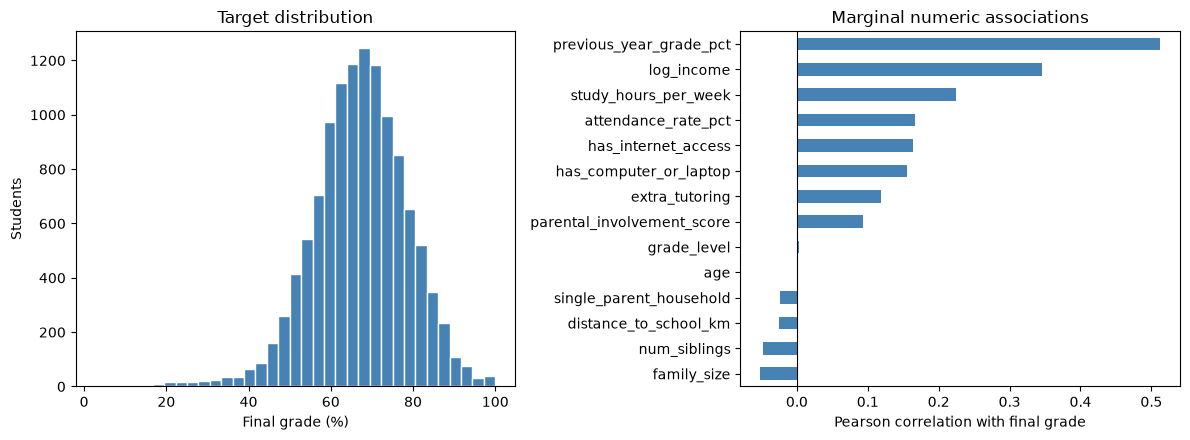

In [2]:
data_path = Path("student_grade_ses_dataset.csv")
if not data_path.exists():
    data_path = Path("ST5227-Course-Project") / data_path.name
assert data_path.exists(), f"Dataset not found: {data_path}"

df = pd.read_csv(data_path)
raw_n = len(df)
df = df.drop_duplicates().set_index("student_id")
assert df.index.is_unique and df[TARGET].notna().all()
assert (df["annual_family_income_inr"].dropna() > 0).all()
df["log_income"] = np.log(df["annual_family_income_inr"])
df = df.drop(columns="annual_family_income_inr")

CONTINUOUS_COLS = ["distance_to_school_km", "study_hours_per_week",
                   "attendance_rate_pct", "previous_year_grade_pct", "log_income"]
DISCRETE_COLS = ["age", "grade_level", "family_size", "num_siblings",
                 "single_parent_household", "has_internet_access",
                 "has_computer_or_laptop", "extra_tutoring",
                 "parental_involvement_score"]
CATEGORICAL_COLS = ["academic_year", "gender", "school_type", "residence_type",
                    "family_income_bracket", "father_education_level",
                    "mother_education_level", "father_occupation",
                    "mother_occupation", "scholarship_status"]
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS
X = df[PREDICTOR_COLS].copy()
y = df[TARGET].copy()

print(f"{raw_n:,} records; {raw_n - len(df)} exact duplicates removed; {len(df):,} students remain")
print(f"{len(PREDICTOR_COLS)} raw predictors: {len(CONTINUOUS_COLS)} continuous, "
      f"{len(DISCRETE_COLS)} discrete, {len(CATEGORICAL_COLS)} categorical")
print(f"{X.isna().any(axis=1).sum():,} rows have a missing predictor")
print("Most missing predictors:")
print(X.isna().mean().sort_values(ascending=False).head(8).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(y, bins=35, color="steelblue", edgecolor="white")
axes[0].set(xlabel="Final grade (%)", ylabel="Students", title="Target distribution")
X[NUMERIC_COLS].corrwith(y).sort_values().plot.barh(ax=axes[1], color="steelblue")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Pearson correlation with final grade",
            title="Marginal numeric associations")
plt.tight_layout()
plt.show()


## Shared split and distance representation

Match the original stratified 85/15 split exactly. Only the initial split uses `grade_class`; it never enters a model. Within each training fold, impute numeric values by median and categorical values by mode, standardize numeric columns, and one-hot encode categories with a reference level dropped. Numeric coordinates are in standard-deviation units; a dummy mismatch contributes one unit to Euclidean distance. This is a modeling choice, and the relative importance of categorical groups still depends on their number of dummies.

Compare all encoded columns with a compact set of **10 fold-selected encoded columns**. The screen uses the univariate `f_regression` score on training rows only. It can select individual category levels and can miss predictors that matter only through interactions. Treat it as a distance-space experiment, not definitive feature importance. Preprocessing and screening are re-fitted in *every inner and outer fold*.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=df["grade_class"], random_state=SEED
)
print("Training:", X_train.shape, "| test:", X_test.shape)

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("numeric", make_pipeline(SimpleImputer(strategy="median"),
                                      StandardScaler()), NUMERIC_COLS),
            ("categorical", make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(drop="first", handle_unknown="ignore",
                              sparse_output=False)), CATEGORICAL_COLS),
        ], verbose_feature_names_out=False,
    )

def make_knn(feature_count, k, weights):
    return make_pipeline(make_preprocessor(), SelectKBest(f_regression, k=feature_count),
                         KNeighborsRegressor(n_neighbors=k, weights=weights,
                                             metric="euclidean", n_jobs=-1))


Training: (10200, 24) | test: (1800, 24)


In [4]:
def median_pairwise_distance(A_fit):
    # Use predictors from the training fold only to set a comparable bandwidth scale.
    rng = np.random.default_rng(SEED)
    sample_idx = rng.choice(len(A_fit), size=min(512, len(A_fit)), replace=False)
    sample = np.asarray(A_fit[sample_idx], dtype=float)
    distances = euclidean_distances(sample, sample)
    reference = np.median(distances[np.triu_indices(len(sample), k=1)])
    if not np.isfinite(reference) or reference <= 0:
        raise ValueError("The training distance scale must be positive and finite")
    return reference


# Check that statsmodels' local-constant Gaussian fit gives the NW weighted mean.
toy_fit = np.array([[0.0], [1.0]])
toy_y = np.array([0.0, 10.0])
toy_model = KernelReg(toy_y, toy_fit, var_type="c", reg_type="lc",
                      ckertype="gaussian", bw=[1.0])
toy_expected = 10 * np.exp(-0.5) / (1 + np.exp(-0.5))
np.testing.assert_allclose(toy_model.fit(np.array([[0.0]]))[0][0], toy_expected)


## Inner-fold tuning of neighborhood size, weighting, and feature count

The grid covers very local through strongly smoothed neighborhoods. Uniform weights reproduce the Week 5 regression formula; inverse-distance weights test whether nearby neighbors deserve more influence. A small `k` tends to fit training rows closely but varies more across samples. A large `k` reduces variance at the cost of local detail. Select the configuration with the lowest **mean inner-validation RMSE**. The same inner folds compare every candidate.

For speed, each prepared inner fold finds up to 500 neighbors once for each feature representation, then evaluates the candidate averages from those neighbors. This is algebraically the same prediction rule used by the final `KNeighborsRegressor`, including its treatment of zero distances. Training errors are collected only for the full-training learning-curve analysis; they do not select settings.

In [5]:
def predict_from_neighbors(distances, indices, fitted_y, k, weights):
    d = distances[:, :k]
    neighbor_y = fitted_y[indices[:, :k]]
    if weights == "uniform":
        return neighbor_y.mean(axis=1)
    zero = d == 0
    w = np.divide(1.0, d, out=np.zeros_like(d), where=~zero)
    has_zero = zero.any(axis=1)
    if has_zero.any():
        w[has_zero] = zero[has_zero].astype(float)
    return (w * neighbor_y).sum(axis=1) / w.sum(axis=1)

def tune_knn(X_fit, y_fit, collect_train=False):
    inner = KFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
    records = []
    for inner_fold, (fit_idx, valid_idx) in enumerate(inner.split(X_fit), start=1):
        X_part, X_valid = X_fit.iloc[fit_idx], X_fit.iloc[valid_idx]
        y_part = y_fit.iloc[fit_idx].to_numpy()
        y_valid = y_fit.iloc[valid_idx].to_numpy()
        prep = make_preprocessor()
        Z_part = prep.fit_transform(X_part)
        Z_valid = prep.transform(X_valid)
        for feature_count in FEATURE_GRID:
            screen = SelectKBest(f_regression, k=feature_count)
            A_part = screen.fit_transform(Z_part, y_part)
            A_valid = screen.transform(Z_valid)
            neighbors = NearestNeighbors(n_neighbors=max(K_GRID),
                                         metric="euclidean", n_jobs=-1).fit(A_part)
            d_valid, i_valid = neighbors.kneighbors(A_valid)
            if inner_fold == 1 and feature_count == 10:
                # Confirm the accelerated candidate scorer matches sklearn's estimator.
                reference = KNeighborsRegressor(n_neighbors=40, weights="distance",
                                                metric="euclidean", n_jobs=1).fit(A_part, y_part)
                np.testing.assert_allclose(
                    predict_from_neighbors(d_valid[:25], i_valid[:25], y_part, 40, "distance"),
                    reference.predict(A_valid[:25]), rtol=1e-12, atol=1e-12,
                )
            if collect_train:
                d_part, i_part = neighbors.kneighbors(A_part)
            for k in K_GRID:
                for weights in WEIGHT_GRID:
                    pred_valid = predict_from_neighbors(d_valid, i_valid, y_part, k, weights)
                    row = {"fold": inner_fold, "features": str(feature_count),
                           "k": k, "weights": weights,
                           "valid_rmse": root_mean_squared_error(y_valid, pred_valid)}
                    if collect_train:
                        pred_part = predict_from_neighbors(d_part, i_part, y_part, k, weights)
                        row["train_rmse"] = root_mean_squared_error(y_part, pred_part)
                    records.append(row)
    scores = pd.DataFrame(records)
    summary = scores.groupby(["features", "k", "weights"], as_index=False).agg(
        mean_valid_rmse=("valid_rmse", "mean"),
        sd_valid_rmse=("valid_rmse", "std"),
        **({"mean_train_rmse": ("train_rmse", "mean")} if collect_train else {})
    )
    chosen = summary.sort_values(["mean_valid_rmse", "k"],
                                 ascending=[True, False]).iloc[0]
    settings = {"features": chosen["features"], "k": int(chosen["k"]),
                "weights": chosen["weights"]}
    return settings, summary


## Nadaraya–Watson kernel regression and bandwidth tuning

For a query student, Gaussian NW predicts the weighted average of **all** training grades, with weight proportional to `exp(−distance² / (2h²))`. The distances use exactly the KNN encoding and Euclidean metric. Unlike KNN's adaptive distance to the `k`th neighbor, NW uses a fixed bandwidth `h` for each fitted model. The candidates above multiply a median pairwise distance computed from at most 512 **training-fold** students, so the search covers comparable relative scales for 10 and all encoded columns. The median uses predictors only. Small bandwidths fit very locally; large bandwidths approach the training mean. The same inner folds and RMSE select both NW bandwidth and feature count.

The Week 5 lab uses `statsmodels.KernelReg` for this estimator. We specify `reg_type="lc"` for **local constant** regression because the library defaults to local linear, and set every encoded coordinate's Gaussian bandwidth to the same `h`. Their product is proportional to the Gaussian kernel of squared Euclidean distance used here. Numeric bandwidths preserve our fold-local grid search instead of invoking the library's separate automatic bandwidth selection. Each candidate requires a kernel fit, so tuning may take longer than a batched implementation.


In [6]:
def tune_nw(X_fit, y_fit):
    inner = KFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
    records = []
    for inner_fold, (fit_idx, valid_idx) in enumerate(inner.split(X_fit), start=1):
        X_part, X_valid = X_fit.iloc[fit_idx], X_fit.iloc[valid_idx]
        y_part = y_fit.iloc[fit_idx].to_numpy()
        y_valid = y_fit.iloc[valid_idx].to_numpy()
        prep = make_preprocessor()
        Z_part = prep.fit_transform(X_part)
        Z_valid = prep.transform(X_valid)
        for feature_count in FEATURE_GRID:
            screen = SelectKBest(f_regression, k=feature_count)
            A_part = screen.fit_transform(Z_part, y_part)
            A_valid = screen.transform(Z_valid)
            reference = median_pairwise_distance(A_part)
            for multiplier in NW_BANDWIDTH_MULTIPLIERS:
                bandwidth = multiplier * reference
                model = KernelReg(
                    y_part, A_part, var_type="c" * A_part.shape[1],
                    reg_type="lc", ckertype="gaussian",
                    bw=np.full(A_part.shape[1], bandwidth),
                )
                prediction = model.fit(A_valid)[0]
                records.append({
                    "fold": inner_fold, "features": str(feature_count),
                    "bandwidth_multiplier": multiplier,
                    "bandwidth": bandwidth,
                    "valid_rmse": root_mean_squared_error(y_valid, prediction),
                })
    scores = pd.DataFrame(records)
    summary = scores.groupby(["features", "bandwidth_multiplier"], as_index=False).agg(
        mean_valid_rmse=("valid_rmse", "mean"),
        sd_valid_rmse=("valid_rmse", "std"),
        mean_bandwidth=("bandwidth", "mean"),
    )
    chosen = summary.sort_values(
        ["mean_valid_rmse", "bandwidth_multiplier"], ascending=[True, False]
    ).iloc[0]
    settings = {
        "features": chosen["features"],
        "bandwidth_multiplier": float(chosen["bandwidth_multiplier"]),
    }
    return settings, summary


## Paired outer-fold comparison

Use the same five shuffled outer folds as `Project-GAMs.ipynb`. Within each outer training fold, tune KNN and NW independently using identical inner folds and fold-local preprocessing. Score every method on the same outer validation students. The forest settings are a fixed reference, not a newly optimized forest. Fold RMSE differences are descriptive because training folds overlap.

In [7]:
outer_cv = KFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=SEED)
cv_rows = []
chosen_settings = []
nw_chosen_settings = []
screened_names = []
for fold, (fit_idx, valid_idx) in enumerate(outer_cv.split(X_train), start=1):
    X_fit, X_valid = X_train.iloc[fit_idx], X_train.iloc[valid_idx]
    y_fit, y_valid = y_train.iloc[fit_idx], y_train.iloc[valid_idx]
    settings, _ = tune_knn(X_fit, y_fit)
    chosen_settings.append({"fold": fold, **settings})
    nw_settings, _ = tune_nw(X_fit, y_fit)
    nw_chosen_settings.append({"fold": fold, **nw_settings})

    # Fit every preprocessing and selection step on this outer training fold.
    fold_prep = make_preprocessor().fit(X_fit)
    Z_fit = fold_prep.transform(X_fit)
    Z_valid = fold_prep.transform(X_valid)
    screen = SelectKBest(f_regression, k=10).fit(Z_fit, y_fit)
    screened_names.extend(fold_prep.get_feature_names_out()[screen.get_support()])
    nw_screen = SelectKBest(
        f_regression, k="all" if nw_settings["features"] == "all" else 10
    ).fit(Z_fit, y_fit)
    A_fit = nw_screen.transform(Z_fit)
    A_valid = nw_screen.transform(Z_valid)
    nw_bandwidth = (nw_settings["bandwidth_multiplier"]
                    * median_pairwise_distance(A_fit))
    nw_model = KernelReg(
        y_fit.to_numpy(), A_fit, var_type="c" * A_fit.shape[1],
        reg_type="lc", ckertype="gaussian",
        bw=np.full(A_fit.shape[1], nw_bandwidth),
    )
    nw_pred = nw_model.fit(A_valid)[0]

    models = {
        "Mean only": DummyRegressor(strategy="mean"),
        "OLS": LinearRegression(),
        "Random forest (reference)": RandomForestRegressor(
            **FOREST_SETTINGS, random_state=SEED + fold),
        "KNN": make_knn("all" if settings["features"] == "all" else 10,
                        settings["k"], settings["weights"]),
    }
    for name, model in models.items():
        if name == "KNN":
            model.fit(X_fit, y_fit)
            pred = model.predict(X_valid)
        else:
            model.fit(Z_fit, y_fit)
            pred = model.predict(Z_valid)
        cv_rows.append({"fold": fold, "model": name,
                        "rmse": root_mean_squared_error(y_valid, pred)})
    cv_rows.append({"fold": fold, "model": "Nadaraya-Watson",
                    "rmse": root_mean_squared_error(y_valid, nw_pred)})
    print(f"Outer fold {fold}/{OUTER_SPLITS}: KNN {settings}; NW {nw_settings}")

cv_scores = pd.DataFrame(cv_rows)
cv_wide = cv_scores.pivot(index="fold", columns="model", values="rmse")
cv_summary = cv_scores.groupby("model")["rmse"].agg(mean_rmse="mean", sd_rmse="std")
print("\nPaired outer-fold RMSE (grade points):")
print(cv_summary.sort_values("mean_rmse").round(3).to_string())
print("\nKNN settings by fold:")
print(pd.DataFrame(chosen_settings).to_string(index=False))
print("\nNW settings by fold:")
print(pd.DataFrame(nw_chosen_settings).to_string(index=False))


Outer fold 1/5: KNN {'features': '10', 'k': 100, 'weights': 'distance'}; NW {'features': '10', 'bandwidth_multiplier': 0.2}
Outer fold 2/5: KNN {'features': '10', 'k': 100, 'weights': 'distance'}; NW {'features': '10', 'bandwidth_multiplier': 0.2}
Outer fold 3/5: KNN {'features': '10', 'k': 100, 'weights': 'distance'}; NW {'features': '10', 'bandwidth_multiplier': 0.2}
Outer fold 4/5: KNN {'features': '10', 'k': 100, 'weights': 'distance'}; NW {'features': '10', 'bandwidth_multiplier': 0.2}
Outer fold 5/5: KNN {'features': '10', 'k': 40, 'weights': 'uniform'}; NW {'features': '10', 'bandwidth_multiplier': 0.2}

Paired outer-fold RMSE (grade points):
                           mean_rmse  sd_rmse
model                                        
OLS                            9.629    0.215
Random forest (reference)      9.832    0.198
Nadaraya-Watson                9.942    0.150
KNN                            9.944    0.149
Mean only                     11.697    0.090

KNN settings by fol

NW minus KNN: mean paired outer-fold difference = -0.002 points
NW minus OLS: mean paired outer-fold difference = +0.313 points
NW minus Random forest (reference): mean paired outer-fold difference = +0.110 points


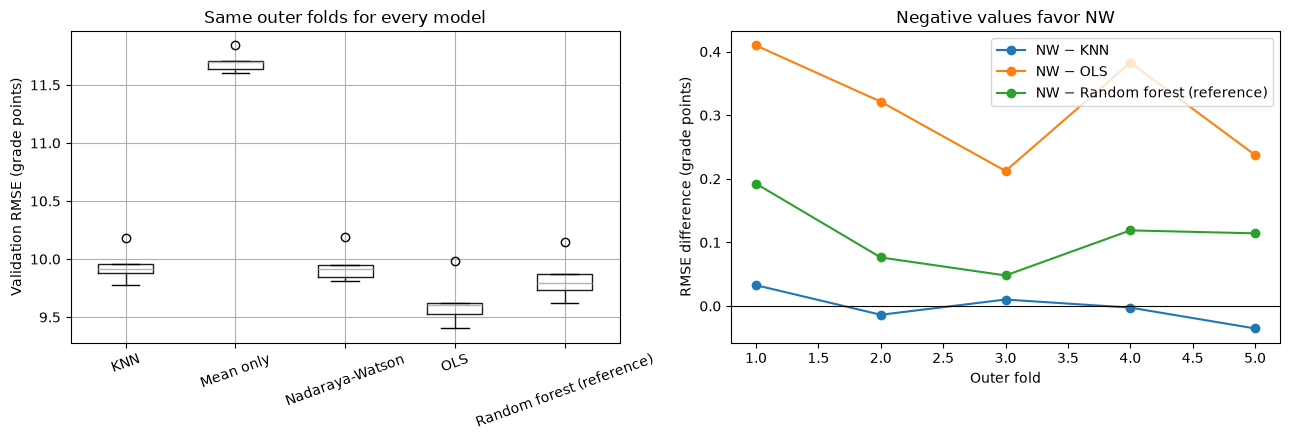

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cv_wide.boxplot(ax=axes[0], rot=20)
axes[0].set(ylabel="Validation RMSE (grade points)",
            title="Same outer folds for every model")
for name in ["KNN", "OLS", "Random forest (reference)"]:
    difference = cv_wide["Nadaraya-Watson"] - cv_wide[name]
    axes[1].plot(difference.index, difference, marker="o", label=f"NW − {name}")
    print(f"NW minus {name}: mean paired outer-fold difference = {difference.mean():+.3f} points")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="Outer fold", ylabel="RMSE difference (grade points)",
            title="Negative values favor NW")
axes[1].legend()
plt.tight_layout()
plt.show()

## Feature-screen stability

The counts below show how often an encoded column entered the *top ten univariate screen* over five outer training folds. This screen is neither multivariable importance nor a causal effect. A category can contribute multiple dummy columns. KNN itself has no regression coefficients.

study_hours_per_week                      5
attendance_rate_pct                       5
previous_year_grade_pct                   5
log_income                                5
has_internet_access                       5
family_income_bracket_Low                 5
family_income_bracket_Upper-Middle        5
mother_education_level_Master's Degree    5
father_education_level_Master's Degree    4
has_computer_or_laptop                    3
mother_education_level_Primary            3


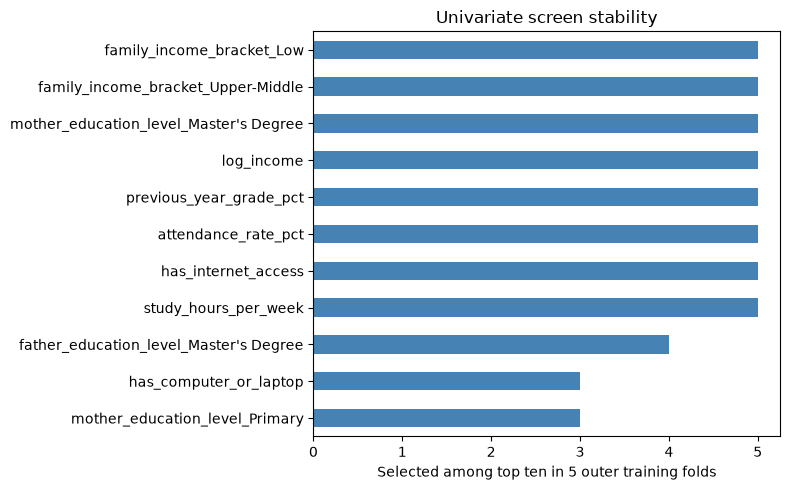

In [9]:
feature_frequency = pd.Series(screened_names).value_counts().rename("folds_selected")
print(feature_frequency.head(20).to_string())
fig, ax = plt.subplots(figsize=(8, 5))
feature_frequency.head(15).sort_values().plot.barh(ax=ax, color="steelblue")
ax.set(xlabel=f"Selected among top ten in {OUTER_SPLITS} outer training folds",
       title="Univariate screen stability")
plt.tight_layout()
plt.show()


## Full-training tuning and bias–variance curve

Repeat inner CV using all training rows. The graph shows training and validation RMSE against neighbor count for both feature representations and both weighting rules. **Inverse-distance weighting interpolates every training row here:** its distance to itself is zero, so its resubstitution training RMSE is zero at *every* `k`, not just `k=1`. Uniform weights also have zero training RMSE at `k=1`, then increasingly average across neighbors. These training scores do not select the model; the validation curve does. Fold standard-error bars describe variation in three inner-validation folds, not a formal population confidence interval. Differences between representations show how the distance definition affects KNN.

Selected from full-training inner CV: {'features': '10', 'k': 100, 'weights': 'distance'}

Top candidate settings:
features   k  weights  mean_valid_rmse  sd_valid_rmse  mean_train_rmse
      10 100 distance            9.952          0.118            0.000
      10 100  uniform            9.958          0.120            9.838
      10  40  uniform            9.975          0.118            9.701
      10  40 distance            9.990          0.118            0.000
      10 250 distance            9.995          0.117            0.000
      10 250  uniform           10.019          0.118            9.961
      10 500 distance           10.059          0.107            0.000
      10 500  uniform           10.094          0.106           10.069
     all 100 distance           10.109          0.102            0.000
     all 100  uniform           10.116          0.102           10.026
     all  40 distance           10.122          0.095            0.000
     all  40  uniform           1

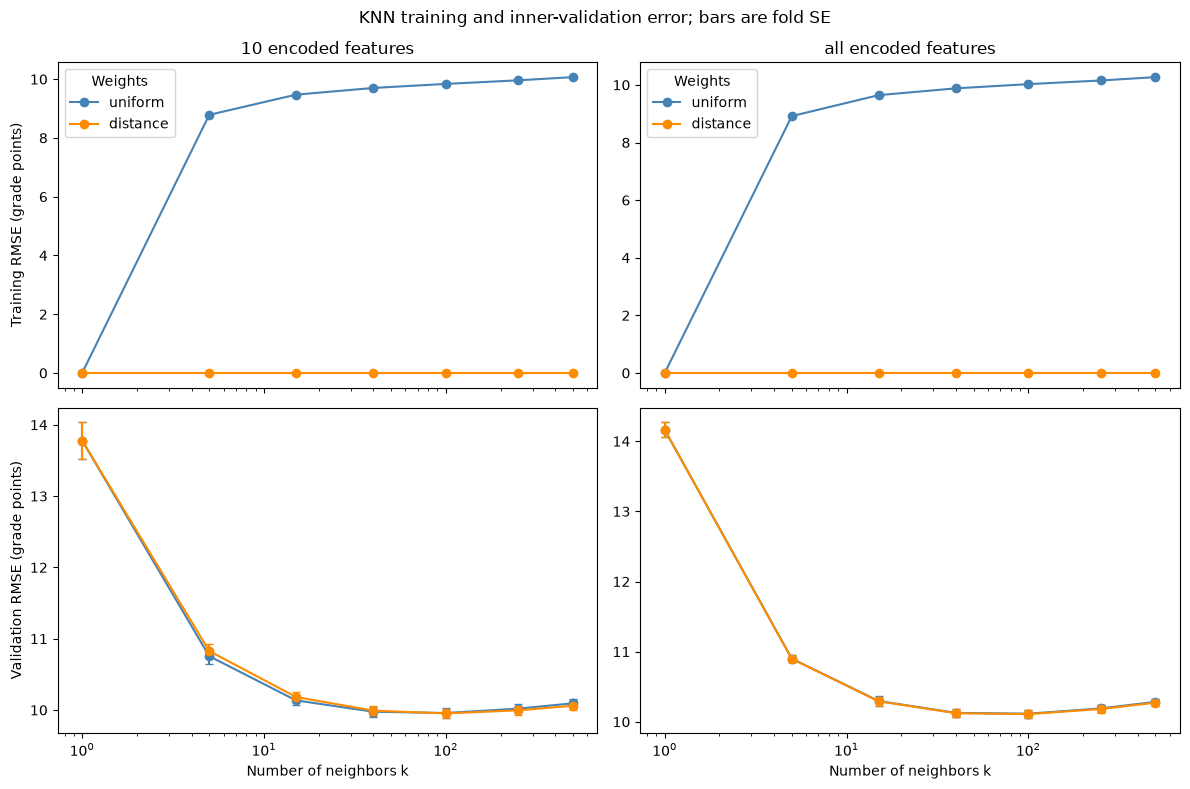

In [10]:
final_settings, full_inner_scores = tune_knn(X_train, y_train, collect_train=True)
print("Selected from full-training inner CV:", final_settings)
print("\nTop candidate settings:")
print(full_inner_scores.nsmallest(12, "mean_valid_rmse").round(3).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex="col")
colors = {"uniform": "steelblue", "distance": "darkorange"}
for column, feature_count in enumerate(["10", "all"]):
    for weights in WEIGHT_GRID:
        sub = full_inner_scores.loc[(full_inner_scores["features"] == feature_count)
                                    & (full_inner_scores["weights"] == weights)].sort_values("k")
        axes[0, column].plot(sub["k"], sub["mean_train_rmse"], marker="o",
                             color=colors[weights], label=weights)
        axes[1, column].errorbar(sub["k"], sub["mean_valid_rmse"],
                                 yerr=sub["sd_valid_rmse"] / np.sqrt(INNER_SPLITS),
                                 marker="o", capsize=3, color=colors[weights], label=weights)
    axes[0, column].set(title=f"{feature_count} encoded features", xscale="log")
    axes[1, column].set(xlabel="Number of neighbors k", xscale="log")
    axes[0, column].legend(title="Weights")
axes[0, 0].set_ylabel("Training RMSE (grade points)")
axes[1, 0].set_ylabel("Validation RMSE (grade points)")
fig.suptitle("KNN training and inner-validation error; bars are fold SE")
plt.tight_layout()
plt.show()


## Bandwidth–validation error curve

Retune NW on all training rows. The curves show inner-validation RMSE across relative bandwidths for both encoded feature spaces. Bars are standard errors across the three inner folds, not population confidence intervals. The reported `h` is the mean absolute bandwidth across those folds; each fold computes its own predictor-only distance scale. At small bandwidths the fit is highly local and variable; at large bandwidths many observations receive similar weights, so the model approaches a mean-only prediction. These validation scores, not resubstitution training error, select the final NW model.

Selected NW settings from full-training inner CV: {'features': '10', 'bandwidth_multiplier': 0.2}

Top NW candidates:
features  bandwidth_multiplier  mean_valid_rmse  sd_valid_rmse  mean_bandwidth
      10                  0.20            9.961          0.128           0.640
     all                  0.20           10.190          0.106           1.218
      10                  0.40           10.309          0.090           1.279
      10                  0.10           10.526          0.239           0.320
     all                  0.40           10.902          0.048           2.436
      10                  0.80           11.032          0.065           2.558
     all                  0.80           11.444          0.041           4.872
      10                  1.60           11.490          0.039           5.116
     all                  1.60           11.628          0.040           9.745
      10                  0.05           11.809          0.479           0.160
     all     

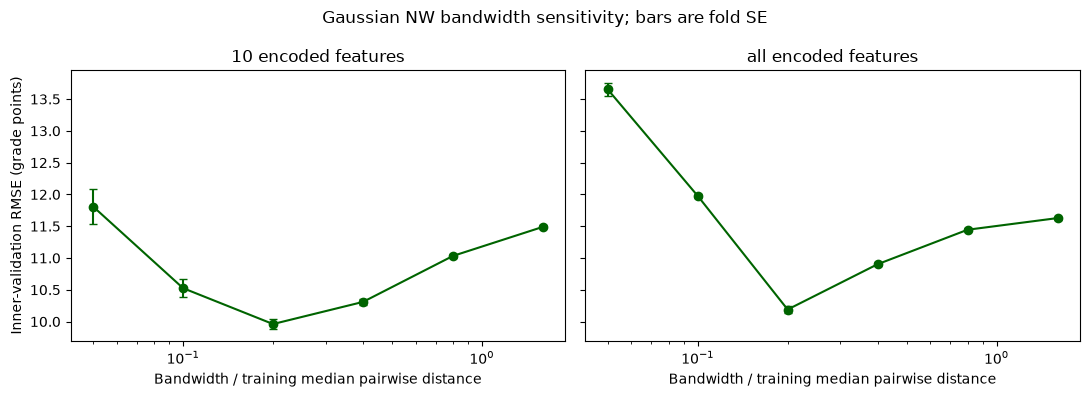

In [11]:
final_nw_settings, full_nw_inner_scores = tune_nw(X_train, y_train)
print("Selected NW settings from full-training inner CV:", final_nw_settings)
print("\nTop NW candidates:")
print(full_nw_inner_scores.nsmallest(12, "mean_valid_rmse").round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, feature_count in zip(axes, ["10", "all"]):
    sub = full_nw_inner_scores.loc[
        full_nw_inner_scores["features"] == feature_count
    ].sort_values("bandwidth_multiplier")
    ax.errorbar(sub["bandwidth_multiplier"], sub["mean_valid_rmse"],
                yerr=sub["sd_valid_rmse"] / np.sqrt(INNER_SPLITS),
                marker="o", capsize=3, color="darkgreen")
    ax.set(xscale="log", xlabel="Bandwidth / training median pairwise distance",
           title=f"{feature_count} encoded features")
axes[0].set_ylabel("Inner-validation RMSE (grade points)")
fig.suptitle("Gaussian NW bandwidth sensitivity; bars are fold SE")
plt.tight_layout()
plt.show()

## Final fits on the shared test partition

Fit both tuned local regressors and reference models on all training rows. The test scores are an additional check only: this partition has been viewed in `Project.ipynb` and `Project-GAMs.ipynb`. The paired bootstrap resamples test **students**, holding fitted models fixed. Its intervals omit retraining and hyperparameter-selection uncertainty and should not be used to claim a new, independent discovery.

In [12]:
final_knn = make_knn("all" if final_settings["features"] == "all" else 10,
                     final_settings["k"], final_settings["weights"])
final_knn.fit(X_train, y_train)
final_prep = make_preprocessor().fit(X_train)
Z_train = final_prep.transform(X_train)
Z_test = final_prep.transform(X_test)
final_nw_screen = SelectKBest(
    f_regression, k="all" if final_nw_settings["features"] == "all" else 10
).fit(Z_train, y_train)
A_train = final_nw_screen.transform(Z_train)
A_test = final_nw_screen.transform(Z_test)
final_nw_bandwidth = (final_nw_settings["bandwidth_multiplier"]
                      * median_pairwise_distance(A_train))
final_nw = KernelReg(
    y_train.to_numpy(), A_train, var_type="c" * A_train.shape[1],
    reg_type="lc", ckertype="gaussian",
    bw=np.full(A_train.shape[1], final_nw_bandwidth),
)
reference_models = {
    "Mean only": DummyRegressor(strategy="mean"),
    "OLS": LinearRegression(),
    "Random forest (reference)": RandomForestRegressor(
        **FOREST_SETTINGS, random_state=SEED),
}
test_predictions = {"KNN": final_knn.predict(X_test),
                    "Nadaraya-Watson": final_nw.fit(A_test)[0]}
for name, model in reference_models.items():
    model.fit(Z_train, y_train)
    test_predictions[name] = model.predict(Z_test)
test_rmse = pd.Series({name: root_mean_squared_error(y_test, pred)
                       for name, pred in test_predictions.items()}, name="test_rmse")
print("Test RMSE (grade points; corroborative):")
print(test_rmse.sort_values().round(3).to_string())

if final_settings["features"] != "all":
    names = final_knn.named_steps["columntransformer"].get_feature_names_out()
    selected = names[final_knn.named_steps["selectkbest"].get_support()]
    print("\nSelected encoded features in final KNN:")
    print("\n".join(selected))

print(f"\nFinal NW bandwidth h: {final_nw.bw[0]:.3f}")
rng = np.random.default_rng(SEED)
test_y = y_test.to_numpy()
boot_index = rng.integers(0, len(test_y), size=(1000, len(test_y)))
rows = []
for candidate, reference in [("Nadaraya-Watson", "KNN"),
                             ("Nadaraya-Watson", "OLS"),
                             ("Nadaraya-Watson", "Random forest (reference)"),
                             ("KNN", "OLS"),
                             ("KNN", "Random forest (reference)")]:
    candidate_sq = (test_y - test_predictions[candidate]) ** 2
    reference_sq = (test_y - test_predictions[reference]) ** 2
    boot_diff = np.sqrt(candidate_sq[boot_index].mean(axis=1)) - np.sqrt(
        reference_sq[boot_index].mean(axis=1))
    rows.append({"comparison": f"{candidate} − {reference}",
                 "rmse_difference": test_rmse[candidate] - test_rmse[reference],
                 "ci_lower": np.quantile(boot_diff, 0.025),
                 "ci_upper": np.quantile(boot_diff, 0.975)})
comparison = pd.DataFrame(rows).set_index("comparison")
print("\nConditional paired test bootstrap intervals:")
print(comparison.round(3).to_string())


Test RMSE (grade points; corroborative):
OLS                           9.813
Random forest (reference)    10.032
Nadaraya-Watson              10.044
KNN                          10.072
Mean only                    11.708

Selected encoded features in final KNN:
study_hours_per_week
attendance_rate_pct
previous_year_grade_pct
log_income
has_internet_access
has_computer_or_laptop
family_income_bracket_Low
family_income_bracket_Upper-Middle
father_education_level_Master's Degree
mother_education_level_Master's Degree

Final NW bandwidth h: 0.669

Conditional paired test bootstrap intervals:
                                             rmse_difference  ci_lower  ci_upper
comparison                                                                      
Nadaraya-Watson − KNN                                 -0.027    -0.066     0.016
Nadaraya-Watson − OLS                                  0.231     0.088     0.360
Nadaraya-Watson − Random forest (reference)            0.012    -0.129     0.148


## Diagnostics and interpretation

Inspect residuals for both local methods to see whether either leaves systematic structure. KNN and NW are both local **constant** averages; they differ in how distances become weights. KNN retains the `k` nearest observations, so its neighborhood radius adapts to local data density. Gaussian NW uses one fitted bandwidth and gives every observation nonzero weight. Both require retaining training observations for each prediction and depend strongly on scaling, selected features, and one-hot representation. With many encoded coordinates, proximity can become less informative. A poor result for either method does not prove that the grade relationship is globally linear. Neither feature associations nor predictions are causal. The fixed forest is a reference, and the shared test partition has already been inspected. The rubric's separate unsupervised-learning requirement is outside this local-regression analysis.

KNN mean test residual: +0.164 points
Nadaraya-Watson mean test residual: +0.136 points


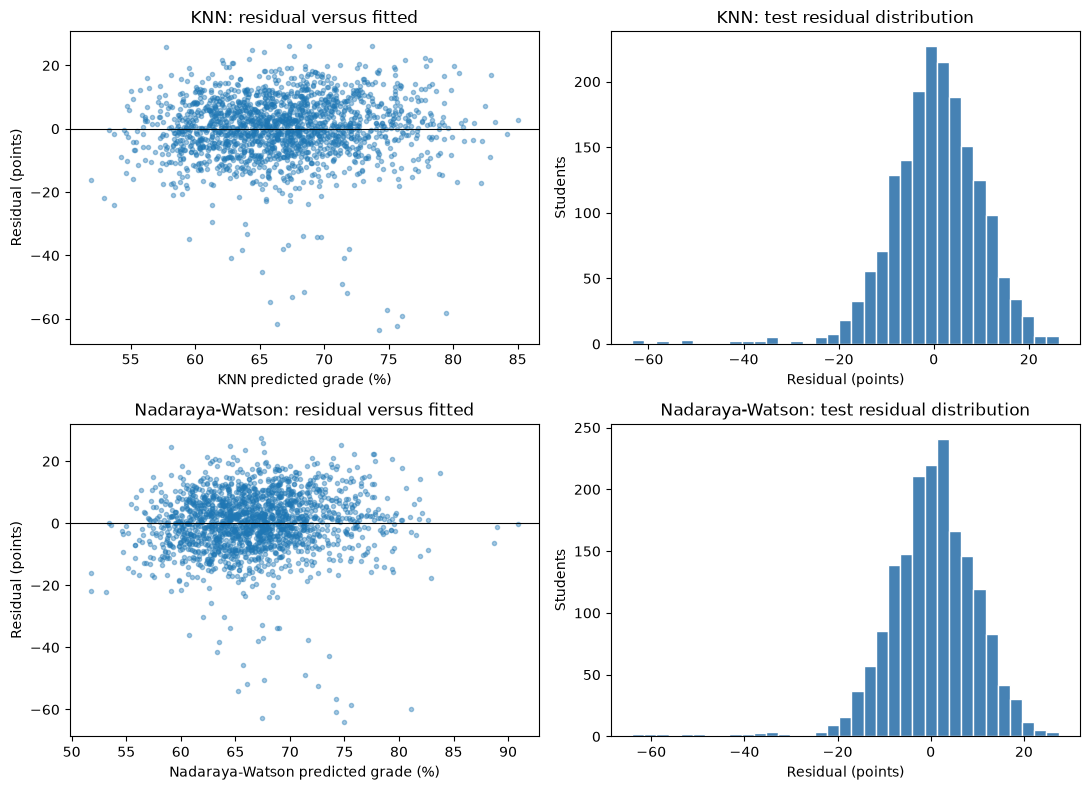

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, name in enumerate(["KNN", "Nadaraya-Watson"]):
    residual = test_y - test_predictions[name]
    axes[row, 0].scatter(test_predictions[name], residual, s=9, alpha=0.4)
    axes[row, 0].axhline(0, color="black", linewidth=0.8)
    axes[row, 0].set(xlabel=f"{name} predicted grade (%)", ylabel="Residual (points)",
                     title=f"{name}: residual versus fitted")
    axes[row, 1].hist(residual, bins=35, color="steelblue", edgecolor="white")
    axes[row, 1].set(xlabel="Residual (points)", ylabel="Students",
                     title=f"{name}: test residual distribution")
    print(f"{name} mean test residual: {residual.mean():+.3f} points")
plt.tight_layout()
plt.show()

## Findings from the verified run

On the same five outer folds, **Nadaraya-Watson (NW) and KNN are effectively tied**: mean validation RMSE is **9.942** and **9.944 grade points**, respectively. The mean paired NW-minus-KNN difference is **-0.002 points**. OLS remains better at **9.629**, with the fixed forest at **9.832** and the mean-only baseline at **11.697**. NW is worse than OLS by **0.313 points** on average. Fold training sets overlap, so these paired differences and fold-to-fold spreads are descriptive, not independent-sample significance tests.

Every outer-fold NW search selects **10 encoded features** and a Gaussian bandwidth equal to **0.2 times that fold's training-only median pairwise distance**. Retuning on all 10,200 training students gives the same settings and a fitted absolute bandwidth **h = 0.669** in the encoded Euclidean space. Its mean inner-validation RMSE is **9.961**, compared with **10.190** for the best full-feature NW candidate. The tuned KNN uses the same compact representation, with **100 neighbors and inverse-distance weights** after full-training retuning. These results emphasize how much the distance representation matters for both local averages.

The NW validation curve rises for very small and very large bandwidths: a narrow kernel makes predictions sensitive to a few nearby outcomes, while a broad kernel averages toward the training mean. KNN instead changes the number of neighbors and adapts its radius to local data density. Neither method fits a local slope. The near tie between their outer-fold errors provides little evidence that replacing a hard neighborhood with Gaussian distance weights improves predictions here.

On the **previously inspected** test partition, NW RMSE is **10.044**, KNN **10.072**, OLS **9.813**, and the forest **10.032**. The paired student-bootstrap interval for NW minus KNN RMSE is **[-0.066, 0.016] points** and includes zero. NW minus OLS is **+0.231 points**, with interval **[0.088, 0.360]**. These intervals hold the fitted models fixed and omit retraining and tuning uncertainty; the test results are corroborative rather than fresh confirmatory evidence. OLS is still the practical prediction choice among these models. The weaker local-constant results could reflect high-dimensional or mixed-variable distance choices, rather than proving that grade effects are exactly linear.